In [ ]:
# cloning the phylogenie repository and loading the library that reads the .nwk tree files.

!git clone https://github.com/gabriele-marino/phylogenie.git
%cd phylogenie
!pip install .
%cd ..

fatal: destination path 'phylogenie' already exists and is not an empty directory.
/content/phylogenie
Processing ./.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for phylogenie: filename=phylogenie-3.12.0-py3-none-any.whl size=44670 sha256=62052a1a72b2718234380c55233444f509b8fc36018b56c7e824319d85d7c935
  Stored in directory: /tmp/pip-ephem-wheel-cache-sxxhghhe/wheels/34/2c/81/30532c792643350bdbcb67b94481f5fd4be79a68a7f233d381
Successfully built phylogenie
  Attempting uninstall: phylogenie
    Found existing installation: phylogenie 3.12.0
    Uninstalling phylogenie-3.12.0:
      Successfully uninstalled phylogenie-3.12.0
/content


In [ ]:
# Loading all needed libraries

import glob
import os
import random
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from phylogenie import load_newick
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras import Model, layers, regularizers

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
/tmp/ipykernel_3810/4021264045.py:12: FutureWarning: phylogenie is no longer maintained; use phyloom instead: https://github.com/gabriele-marino/phyloom
  from phylogenie import load_newick


### Settings (edit this cell only)



In [ ]:
# The dataset to run. The name is the part of the zip file name.
RANGE_TAGS = ["500tips"]

# folder where the zip file is
DATA_DIR = "/content"
# where the zip file is extracted
UNZIP_DIR = "/content/unzipped"

# one training run per each seed
SEEDS = [42, 7, 123]
# dropout inside the attention blocks. The dense layer after poolinng is fixed at 0.10
DROPOUT = 0.1
L2 = 1e-05
SEED = 42
LOSS = "mae"

# keeping trees that survive until the second change time + 1
SURVIVE_MARGIN = 1.0
TARGET_SCORE = 0.10
VAL_FRAC = 0.10
TEST_FRAC = 0.10

EPOCHS = 150
BATCH_SIZE = 32
LEARNING_RATE = 0.0005
PATIENCE = 20


TARGET_NAMES = ["lambda_1", "mu_1", "lambda_2", "mu_2", "lambda_3", "mu_3", "change_time_1", "change_time_2"]
N_OUT = len(TARGET_NAMES)
# column used to remove trees that die out before the second change
LAST_CHANGE = TARGET_NAMES.index("change_time_2")


# Small differences can remain on a GPU.
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

## Loading the data

In [ ]:
def get_zips(tag):
    zips = []
    for z in sorted(glob.glob(os.path.join(DATA_DIR, "3-Interval-*.zip"))):
        name = os.path.basename(z)
        if (tag + "-seed") in name:
            zips.append(z)
    return zips


# Finding the folder of one set (free or different) after the zip files are extracted.
def find_folder(set_name, tag):
    pattern = os.path.join(UNZIP_DIR, "outputs", "3-Interval-ChangeTime-" + set_name + "-*-kept")
    hits = []
    for folder in sorted(glob.glob(pattern)):
        name = os.path.basename(folder)
        if ("-" + tag + "-seed") in name:
            hits.append(folder)
    if len(hits) != 1:
        raise ValueError("Expected one folder for " + set_name + " / " + tag + ", found " + str(hits))
    return hits[0]


# Extracting the zip files and reading the true values of eight parameters of every tree.
def load_parameters(tag):
    zips = get_zips(tag)
    if len(zips) != 2:
        raise ValueError("Tag " + tag + ": expected 2 zips (free and different) in " + DATA_DIR + ", found " + str(zips))
    for z in zips:
        with zipfile.ZipFile(z) as zf:
            zf.extractall(UNZIP_DIR)

    # Reading the free set first, then the different set.
    y_parts = []
    tree_folder = []
    tree_id = []
    tree_set = []
    for set_name in ["free", "different"]:
        folder = find_folder(set_name, tag)
        y = np.load(os.path.join(folder, "y.npy"))
        ids = np.load(os.path.join(folder, "file_ids.npy"))
        columns = []
        with open(os.path.join(folder, "y_columns.txt"), "r") as f:
            for line in f:
                if line.strip():
                    columns.append(line.strip())
        selected = []
        for name in TARGET_NAMES:
            if name not in columns:
                raise ValueError("Column " + name + " is not in y_columns.txt of " + folder)
            selected.append(columns.index(name))
        y_parts.append(y[:, selected])
        for k in range(len(ids)):
            tree_folder.append(folder)
            tree_id.append(ids[k])
            tree_set.append(set_name)
        print("  %-10s %5d trees  (%s)" % (set_name, len(ids), os.path.basename(folder)))

    y_all = np.concatenate(y_parts, axis=0).astype(np.float32)
    return y_all, tree_folder, tree_id, np.array(tree_set)

## Input Representation (Turning tree into an event timeline)

The 7 numbers of every event are 1 (time), 2 (gap to the previous event), 3 (birth), 4 (sampled ancestor), 5 (tip). 6 (lineages before the event), 7 (real event (1) or padding (0))

In [ ]:
# Turning one tree file into a list of events, one row per event, with 7 numbers each.
def read_tree_events(path):
    # Returns the event matrix (m, 7), the time of the last sample and the stem length of one tree.
    tree = load_newick(path)[0]
    stem = float(tree.branch_length or 0.0)

    # Time of every node from the origin, the time of its parent and its own branch length.
    t_abs = {tree: stem}
    for node in tree.iter_preorder():
        if node is tree:
            continue
        t_abs[node] = t_abs[node.parent] + float(node.branch_length or 0.0)

    # Sorting the nodes into births, sampled ancestors and tips. A sampled ancestor is a leaf with branch length 0.
    births = []
    sampled_ancestors = []
    tips = []
    last_time = stem
    for node in tree.iter_preorder():
        if t_abs[node] > last_time:
            last_time = t_abs[node]
        if node.is_leaf():
            if float(node.branch_length or 0.0) == 0.0 and node is not tree:
                sampled_ancestors.append(t_abs[node])
            else:
                tips.append(t_abs[node])
        else:
            has_zero_leaf = False
            for child in node.children:
                if child.is_leaf() and float(child.branch_length or 0.0) == 0.0:
                    has_zero_leaf = True
            if not has_zero_leaf:
                births.append(t_abs[node])

    # Putting all events in time order.
    times = np.array(births + sampled_ancestors + tips)
    kinds = np.array([0] * len(births) + [1] * len(sampled_ancestors) + [2] * len(tips))
    order = np.argsort(times, kind="stable")
    times = times[order]
    kinds = kinds[order]

    # Number of lineages before each event, plus 1 at a birth, minus 1 at a tip, no change at a sampled ancestor. The stem starts with 1 lineage.
    lineage_change = np.zeros(len(times))
    for k in range(len(times)):
        if kinds[k] == 0:
            lineage_change[k] = 1.0
        elif kinds[k] == 2:
            lineage_change[k] = -1.0
    lineages_before = 1.0 + np.concatenate([[0.0], np.cumsum(lineage_change)[:-1]])
    gaps = np.diff(np.concatenate([[0.0], times]))

    # The 7 numbers of every event.
    m = len(times)
    events = np.zeros((m, 7), dtype=np.float32)
    events[:, 0] = times / 10.0
    events[:, 1] = gaps * 10.0
    events[:, 2] = (kinds == 0)
    events[:, 3] = (kinds == 1)
    events[:, 4] = (kinds == 2)
    events[:, 5] = lineages_before / 50.0
    events[:, 6] = 1.0
    return events, last_time, stem

# keeps each dataset after it is read once, so the trees are read only one time
PREPARED = {}
# file path of every kept tree, in the same order as X and y (used by the plots)
TREE_PATHS = {}
# test indices and test predictions (used by the plots)
PLOT_STORE = {}


# Reading all trees of one dataset, removing trees that die out too early, and padding to the same length.
def prepare_dataset(tag):
    if tag in PREPARED:
        return PREPARED[tag]
    y_all, tree_folder, tree_id, tree_set = load_parameters(tag)

    events_list = []
    last_times = np.zeros(len(tree_id), dtype=np.float32)
    for i in range(len(tree_id)):
        path = os.path.join(tree_folder[i], "data", str(tree_id[i]) + ".nwk")
        events, last_time, stem = read_tree_events(path)
        events_list.append(events)
        last_times[i] = last_time
        if (i + 1) % 2000 == 0:
            print("  read %d / %d trees" % (i + 1, len(tree_id)))

    # Keeping only trees that live until the second change time plus the margin.
    keep = last_times >= (y_all[:, LAST_CHANGE] + SURVIVE_MARGIN)
    print("  trees before filtering %d | kept %d | removed %d" % (len(keep), keep.sum(), (~keep).sum()))

    paths_keep = []
    for i in range(len(keep)):
        if keep[i]:
            paths_keep.append(os.path.join(tree_folder[i], "data", str(tree_id[i]) + ".nwk"))
    TREE_PATHS[tag] = paths_keep

    y_keep = y_all[keep]
    set_keep = tree_set[keep]
    kept_events = []
    max_len = 0
    for i in range(len(keep)):
        if keep[i]:
            kept_events.append(events_list[i])
            if len(events_list[i]) > max_len:
                max_len = len(events_list[i])

    # Padding shorter trees with rows of zeros so all trees have the same length. Number 7 of a padded row is 0, so the model can ignore it.
    X = np.zeros((len(kept_events), max_len, 7), dtype=np.float32)
    for i in range(len(kept_events)):
        X[i, :len(kept_events[i]), :] = kept_events[i]

    print("  event timelines:", X.shape, "| longest tree has", max_len, "events")
    PREPARED[tag] = (X, y_keep, set_keep)
    return PREPARED[tag]

## Splitting the trees into training, validation and testing

In [ ]:
# Splitting the trees into train, validation and test sets.
def split_indices(trees_set):
    # 80 / 10 / 10 split, stratified by set (free / different). The seed is fixed, so every model sees the same split.
    all_idx = np.arange(len(trees_set))
    train_idx, rest_idx = train_test_split(all_idx, test_size=VAL_FRAC + TEST_FRAC, random_state=SEED, stratify=trees_set)
    val_idx, test_idx = train_test_split(rest_idx, test_size=TEST_FRAC / (VAL_FRAC + TEST_FRAC), random_state=SEED, stratify=trees_set[rest_idx])
    return train_idx, val_idx, test_idx

## Model and training

In [ ]:
# True when both events are real (channel 7 is 1 for real event and 0 for padding)
class PairMask(layers.Layer):
    def call(self, events):
        real = events[..., 6] > 0.5
        return tf.logical_and(real[:, :, None], real[:, None, :])


class MaskedPool(layers.Layer):
    # mean and max over the real events only
    def call(self, x, events):
        real = tf.cast(events[..., 6:7] > 0.5, x.dtype)
        mean = tf.reduce_sum(x * real, 1) / tf.maximum(tf.reduce_sum(real, 1), 1.0)
        biggest = tf.reduce_max(x + (real - 1.0) * 1e9, 1)
        return tf.concat([mean, biggest], -1)


# Self-attention with 4 heads, then a small dense network. Each part has a residual connection and layer normalisation.
def attention_block(x, width, mask, reg):
    # 4 heads of size width/4. The mask stops events from looking at padded rows.
    attn = layers.MultiHeadAttention(num_heads=4, key_dim=width // 4, dropout=DROPOUT)(x, x, attention_mask=mask)
    x = layers.LayerNormalization()(layers.Add()([x, attn]))
    # Dense part of the block, 64 numbers to 128 and back to 64.
    ff = layers.Dense(2 * width, activation="relu", kernel_regularizer=reg)(x)
    ff = layers.Dense(width, kernel_regularizer=reg)(ff)
    return layers.LayerNormalization()(layers.Add()([x, ff]))


# Building the whole network, from the 7 numbers of each event to the 8 outputs.
def build_attention(n_events, n_channels):
    reg = regularizers.l2(L2) if L2 > 0 else None
    inputs = layers.Input(shape=(n_events, n_channels))
    mask = PairMask()(inputs)
    # First dense layer, turns the 7 numbers of every event into 64 numbers.
    x = layers.Dense(64, activation="relu", kernel_regularizer=reg)(inputs)
    # Two attention blocks.
    x = attention_block(x, 64, mask, reg)
    x = attention_block(x, 64, mask, reg)
    # One vector for the whole tree, mean and max over the real events.
    x = MaskedPool()(x, inputs)
    # Dense layers with dropout. Dropout switches off 10 percent of the numbers at random during training, which helps from overfitting.
    x = layers.Dense(64, activation="relu", kernel_regularizer=reg)(x)
    x = layers.Dropout(0.10)(x)
    x = layers.Dense(32, activation="relu", kernel_regularizer=reg)(x)

    # Eight small branches, one for each value to estimate, each ending in one number.
    outputs = []
    for k in range(N_OUT):
        branch = layers.Dense(32, activation="relu", kernel_regularizer=reg)(x)
        outputs.append(layers.Dense(1)(branch))
    outputs = layers.Concatenate()(outputs)
    return Model(inputs=inputs, outputs=outputs)


# Training one network with one seed. Training stops when the validation loss has not improved for PATIENCE epochs, and the best weights are kept.
def train_model(X_train, y_train_scaled, X_val, y_val_scaled, seed):
    tf.keras.backend.clear_session()
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

    model = build_attention(X_train.shape[1], X_train.shape[2])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE), loss=LOSS)
    # Early stopping, and reducing the learning rate by half when the validation loss stops improving.
    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=7, min_lr=1e-6, verbose=1),
    ]
    history = model.fit(X_train, y_train_scaled, validation_data=(X_val, y_val_scaled),
                        epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=callbacks, verbose=2)
    return model, history.history

## Evaluation

In [ ]:
# The scores
METRIC_COLUMNS = ["Mean RAE", "Median RAE", "Mean MAE", "Median MAE", "MSE", "R2", "Bias"]


# Scores of each value. RAE is the absolute error divided by the true value.
def compute_metrics(y_true, y_pred, names=TARGET_NAMES):
    rows = []
    for j in range(len(names)):
        diff = y_pred[:, j] - y_true[:, j]
        abs_err = np.abs(diff)
        rel_err = abs_err / np.maximum(np.abs(y_true[:, j]), 1e-8)
        ss_res = np.sum(diff ** 2)
        ss_tot = np.sum((y_true[:, j] - y_true[:, j].mean()) ** 2)
        rows.append([rel_err.mean(), np.median(rel_err),
                     abs_err.mean(), np.median(abs_err),
                     np.mean(diff ** 2),
                     1.0 - ss_res / ss_tot,
                     diff.mean()])
    return pd.DataFrame(rows, index=names, columns=METRIC_COLUMNS)


def overall_score(table):
    # averaging over the parameters of the median RAE
    return float(table["Median RAE"].mean())


# Estimated against true value for each of the 8 values. The dashed line is a perfect estimate.
def plot_actual_vs_predicted(y_true, y_pred, test_set, title):
    colors = {"free": "#1f77b4", "different": "#d95f02"}
    fig, axes = plt.subplots(2, 4, figsize=(22, 9.5))
    axes = axes.ravel()
    for j in range(N_OUT):
        actual = y_true[:, j]
        predicted = y_pred[:, j]
        for set_name in ["free", "different"]:
            mask = test_set == set_name
            axes[j].scatter(actual[mask], predicted[mask], s=6, alpha=0.35, color=colors[set_name], label=set_name)
        low = min(actual.min(), predicted.min())
        high = max(actual.max(), predicted.max())
        axes[j].plot([low, high], [low, high], "k--", linewidth=1)
        r2 = 1.0 - np.sum((actual - predicted) ** 2) / np.sum((actual - actual.mean()) ** 2)
        axes[j].set_title("%s   R2 = %.2f" % (TARGET_NAMES[j], r2), fontsize=10)
        axes[j].set_xlabel("actual")
        axes[j].set_ylabel("predicted")
    axes[0].legend(markerscale=3)
    fig.suptitle(title, fontsize=13)
    fig.tight_layout()
    plt.show()

## Running on the datasets

##########################################################################################
DATASET: 500tips
##########################################################################################
  free        8204 trees  (3-Interval-ChangeTime-free-10000-500tips-seed70-kept)
  different   7936 trees  (3-Interval-ChangeTime-different-10000-500tips-seed70-kept)
  read 2000 / 16140 trees
  read 4000 / 16140 trees
  read 6000 / 16140 trees
  read 8000 / 16140 trees
  read 10000 / 16140 trees
  read 12000 / 16140 trees
  read 14000 / 16140 trees
  read 16000 / 16140 trees
  trees before filtering 16140 | kept 16140 | removed 0
  event timelines: (16140, 743, 7) | longest tree has 743 events
  train / val / test: 12912 / 1614 / 1614  (test = 12.5% of the training trees)
------------------------------------------------------------------------------------------
seed 42 (1 of 3)
------------------------------------------------------------------------------------------
Epoch 1/150
404/404 - 

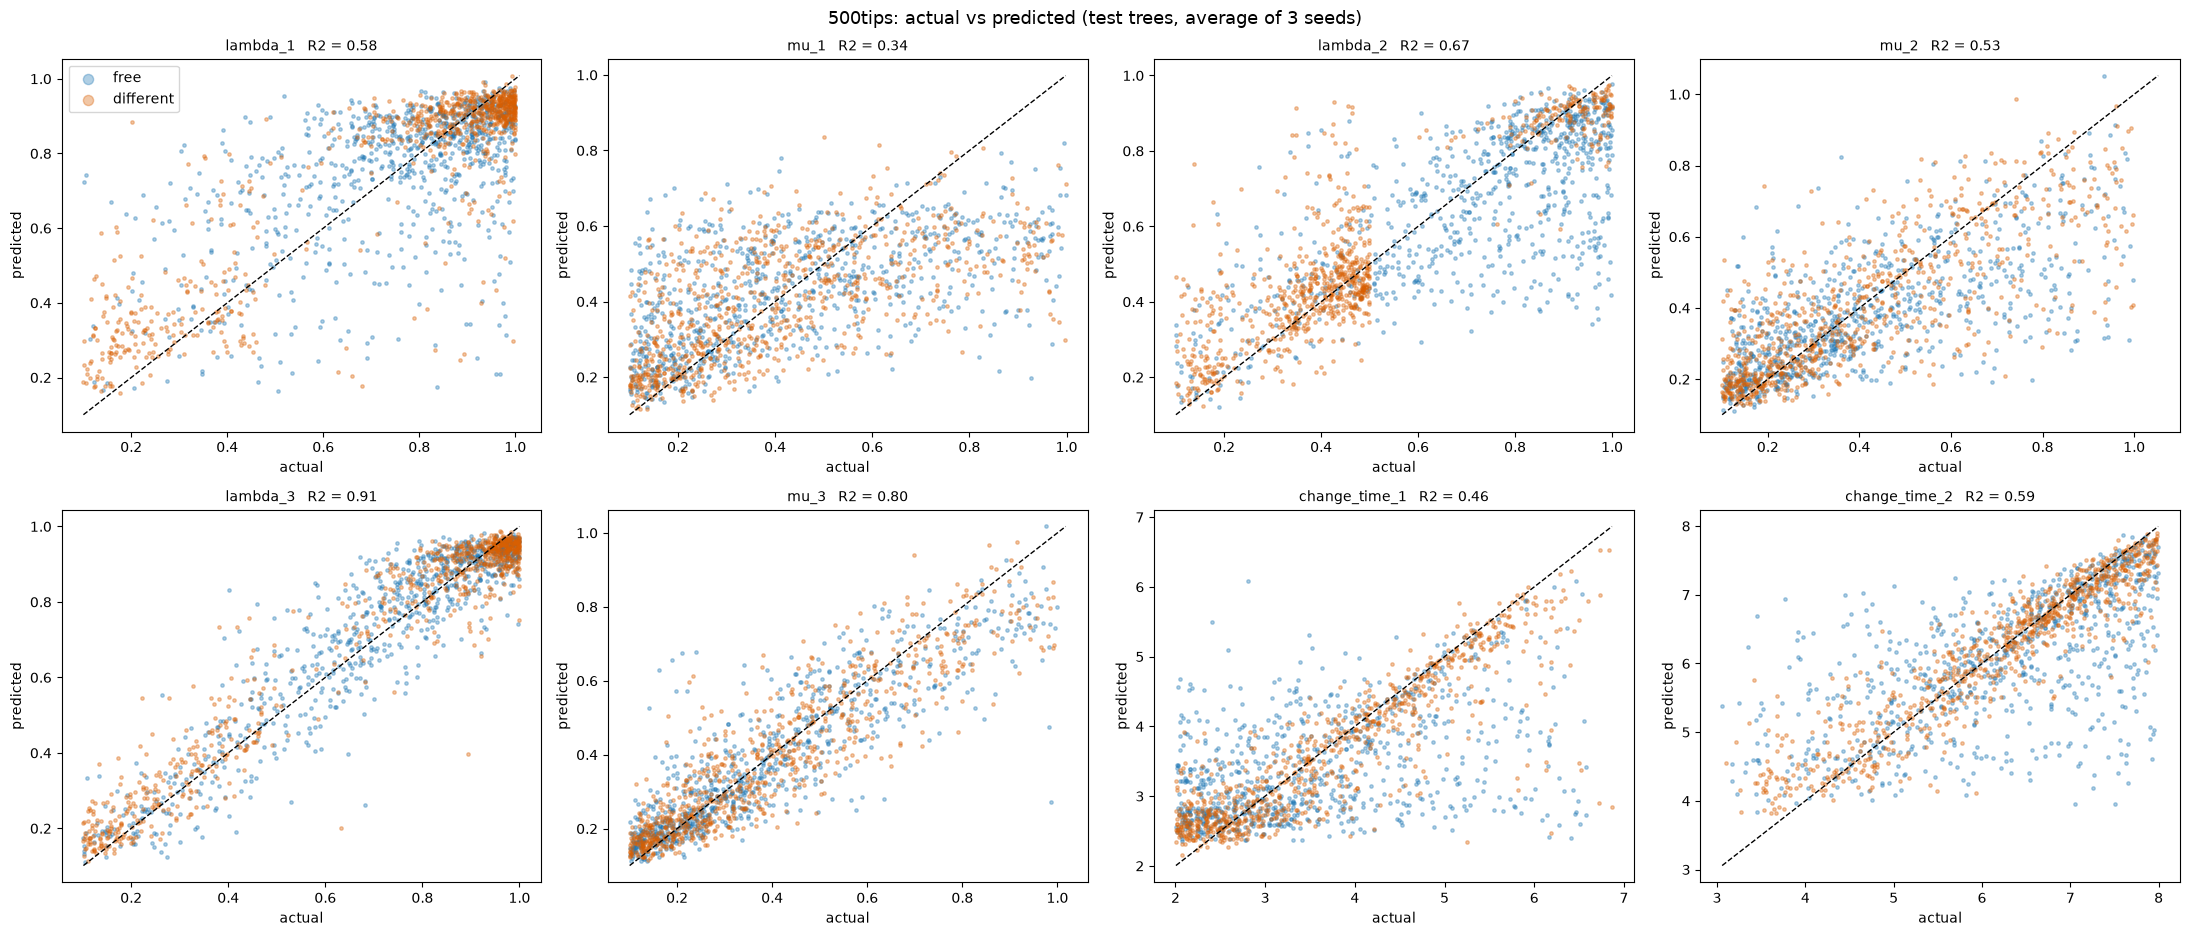

In [ ]:
SEED_SCORES = {}
ALL_HISTORIES = {}

# Reading the trees, scaling the targets, training for each seed, then averaginf and scoring the predictions.
def run_dataset(tag):
    X, y, trees_set = prepare_dataset(tag)

    train_idx, val_idx, test_idx = split_indices(trees_set)
    print("  train / val / test: %d / %d / %d  (test = %.1f%% of the training trees)" %
          (len(train_idx), len(val_idx), len(test_idx), 100.0 * len(test_idx) / len(train_idx)))

    # log + standardising the eight targets (scaler fitted on the training trees only)
    scaler = StandardScaler()
    y_train_scaled = scaler.fit_transform(np.log(np.maximum(y[train_idx], 1e-6)))
    y_val_scaled = scaler.transform(np.log(np.maximum(y[val_idx], 1e-6)))

    # one training run per seed. The final prediction is the average over the seeds (on the log scale)
    all_pred_scaled = []
    for seed in SEEDS:
        print("-" * 90)
        print("seed %d (%d of %d)" % (seed, len(all_pred_scaled) + 1, len(SEEDS)))
        print("-" * 90)
        model, history = train_model(X[train_idx], y_train_scaled, X[val_idx], y_val_scaled, seed)
        if tag not in ALL_HISTORIES:
            ALL_HISTORIES[tag] = {}
        ALL_HISTORIES[tag][seed] = history
        pred_scaled = model.predict(X[test_idx], verbose=0)
        all_pred_scaled.append(pred_scaled)
        single = compute_metrics(y[test_idx], np.exp(scaler.inverse_transform(pred_scaled)))
        print("seed %d: overall error score %.4f | best epoch %d | best validation loss %.4f" %
              (seed, overall_score(single), int(np.argmin(history["val_loss"])) + 1, min(history["val_loss"])))

    # Final prediction. Average of the seeds on the log scale, then converting back to original units.
    pred_scaled = np.mean(all_pred_scaled, axis=0)
    y_pred = np.exp(scaler.inverse_transform(pred_scaled))
    SEED_SCORES[tag] = [overall_score(compute_metrics(y[test_idx], np.exp(scaler.inverse_transform(p)))) for p in all_pred_scaled]
    # Saving the test predictions in a file.
    np.savez("/content/pred_attention_" + tag + ".npz", test_idx=test_idx, y_pred=y_pred)
    PLOT_STORE[tag] = {"test_idx": test_idx, "y_pred": y_pred}
    y_true = y[test_idx]
    test_set = trees_set[test_idx]

    # Scoring on all test trees, and on the free and different trees separately.
    tables = {}
    tables["pooled"] = compute_metrics(y_true, y_pred)
    for set_name in ["free", "different"]:
        mask = test_set == set_name
        tables[set_name] = compute_metrics(y_true[mask], y_pred[mask])

    print()
    print("=" * 90)
    print("RESULTS | %s | %d test trees | average of %d seeds" % (tag, len(test_idx), len(SEEDS)))
    print("=" * 90)
    for key in ["pooled", "free", "different"]:
        n = len(test_idx) if key == "pooled" else int((test_set == key).sum())
        print("\n%s test set (%d trees)" % (key, n))
        print(tables[key].round(4).to_string())
        print("overall error score (average median RAE, target %.2f): %.4f" % (TARGET_SCORE, overall_score(tables[key])))

    plot_actual_vs_predicted(y_true, y_pred, test_set, tag + ": actual vs predicted (test trees, average of %d seeds)" % len(SEEDS))
    return tables

all_tables = {}
for tag in RANGE_TAGS:
    print("#" * 90)
    print("DATASET:", tag)
    print("#" * 90)
    all_tables[tag] = run_dataset(tag)

## Example tree


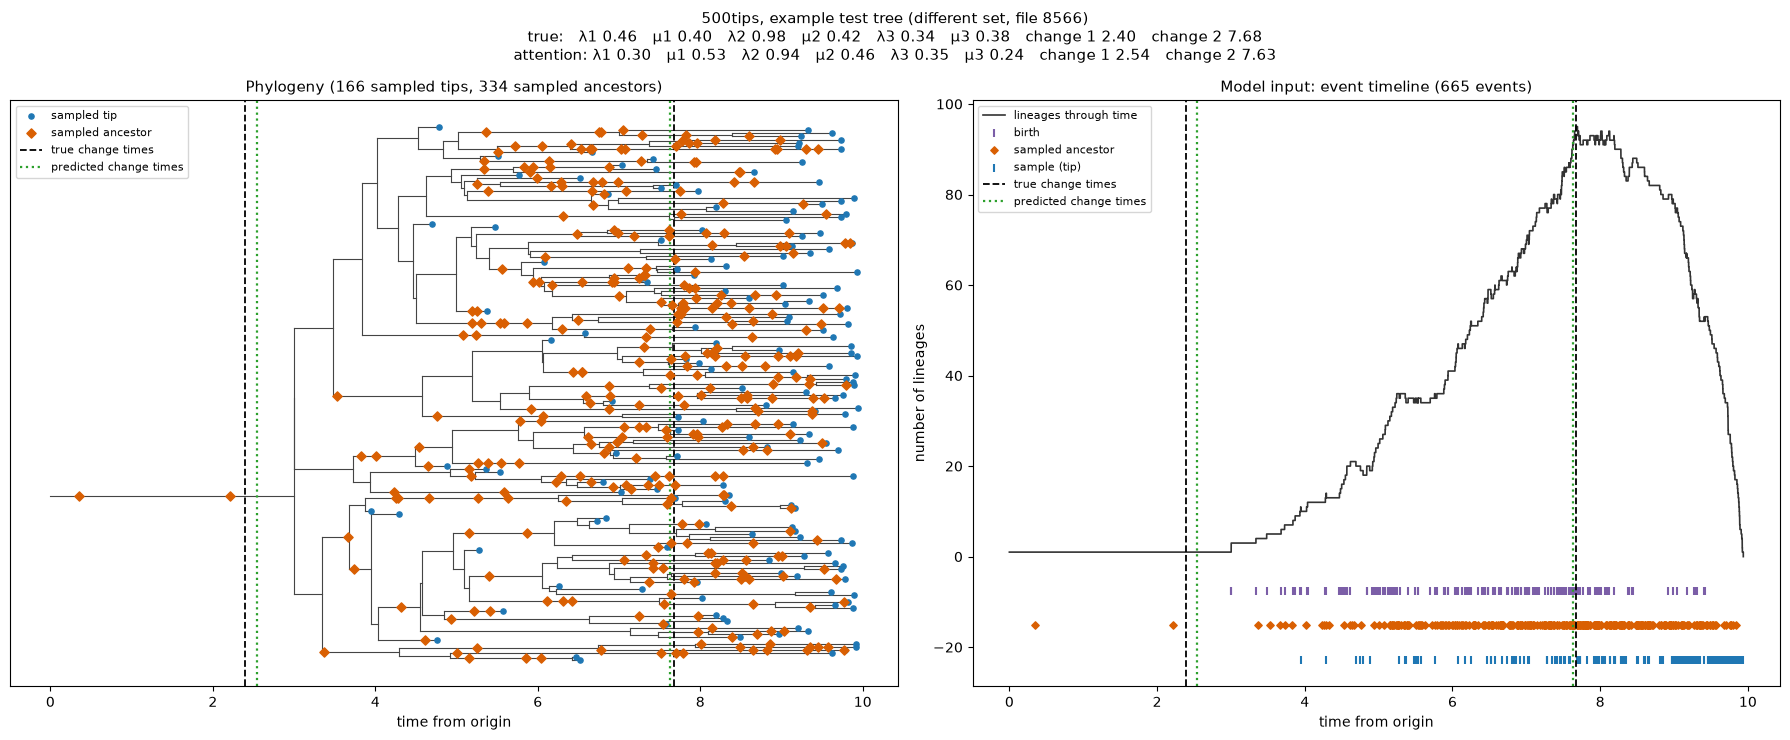

In [ ]:
# Plotting one test tree next to the event timeline that the network reads.

def draw_tree(tree, ax):
    # Drawing the phylogeny on ax. x = time from the origin, y = one row per tip.
    # Tips are blue dots, sampled ancestors are orange diamonds.
    t_abs = {tree: float(tree.branch_length or 0.0)}
    for node in tree.iter_preorder():
        if node is not tree:
            t_abs[node] = t_abs[node.parent] + float(node.branch_length or 0.0)

    def is_sampled_ancestor(node):
        return node.is_leaf() and node is not tree and float(node.branch_length or 0.0) == 0.0

    y_pos = {}
    counter = [0]

    def assign_y(node):
        real_children = []
        for child in node.children:
            if not is_sampled_ancestor(child):
                real_children.append(child)
        if len(real_children) == 0:
            y_pos[node] = counter[0]
            counter[0] = counter[0] + 1
        else:
            total = 0.0
            for child in real_children:
                assign_y(child)
                total = total + y_pos[child]
            y_pos[node] = total / len(real_children)

    assign_y(tree)

    ax.plot([0.0, t_abs[tree]], [y_pos[tree], y_pos[tree]], color="#444444", linewidth=0.8)
    tip_x = []
    tip_y = []
    sa_x = []
    sa_y = []
    for node in tree.iter_preorder():
        if is_sampled_ancestor(node):
            sa_x.append(t_abs[node])
            sa_y.append(y_pos[node.parent])
            continue
        if node is not tree:
            parent = node.parent
            ax.plot([t_abs[parent], t_abs[node]], [y_pos[node], y_pos[node]], color="#444444", linewidth=0.8)
        real_children = []
        for child in node.children:
            if not is_sampled_ancestor(child):
                real_children.append(child)
        if len(real_children) > 1:
            low = min(y_pos[c] for c in real_children)
            high = max(y_pos[c] for c in real_children)
            ax.plot([t_abs[node], t_abs[node]], [low, high], color="#444444", linewidth=0.8)
        if node.is_leaf():
            tip_x.append(t_abs[node])
            tip_y.append(y_pos[node])
    ax.scatter(tip_x, tip_y, s=14, color="#1f77b4", zorder=3, label="sampled tip")
    ax.scatter(sa_x, sa_y, s=22, marker="D", color="#d95f02", zorder=3, label="sampled ancestor")


def plot_example_tree(tag, set_name="different", which=0):
    X, y, trees_set = prepare_dataset(tag)
    store = PLOT_STORE[tag]
    test_idx = store["test_idx"]
    y_pred = store["y_pred"]

    positions = []
    for k in range(len(test_idx)):
        if trees_set[test_idx[k]] == set_name:
            positions.append(k)
    k = positions[which]
    i = test_idx[k]
    path = TREE_PATHS[tag][i]
    file_id = os.path.basename(path).replace(".nwk", "")
    true = y[i]
    pred = y_pred[k]

    events = X[i]
    real = events[:, 6] > 0
    times = events[real, 0] * 10.0
    is_birth = events[real, 2] > 0
    is_sa = events[real, 3] > 0
    is_tip = events[real, 4] > 0
    lineages = 1.0
    step_t = [0.0]
    step_n = [1.0]
    for e in range(len(times)):
        if is_birth[e]:
            lineages = lineages + 1.0
        if is_tip[e]:
            lineages = lineages - 1.0
        step_t.append(times[e])
        step_n.append(lineages)

    tree = load_newick(path)[0]
    n_tips = int(is_tip.sum())
    n_sa = int(is_sa.sum())

    fig, axes = plt.subplots(1, 2, figsize=(18, 7.5), gridspec_kw={"width_ratios": [1.1, 1]})

    draw_tree(tree, axes[0])
    axes[0].set_title("Phylogeny (%d sampled tips, %d sampled ancestors)" % (n_tips, n_sa), fontsize=11)
    axes[0].set_xlabel("time from origin")
    axes[0].set_yticks([])

    axes[1].step(step_t, step_n, where="post", color="#333333", linewidth=1.2, label="lineages through time")
    top = max(step_n)
    axes[1].scatter(times[is_birth], [-0.08 * top] * int(is_birth.sum()), marker="|", s=40, color="#7b5ea7", label="birth")
    axes[1].scatter(times[is_sa], [-0.16 * top] * int(is_sa.sum()), marker="D", s=14, color="#d95f02", label="sampled ancestor")
    axes[1].scatter(times[is_tip], [-0.24 * top] * int(is_tip.sum()), marker="|", s=40, color="#1f77b4", label="sample (tip)")
    axes[1].set_title("Model input: event timeline (%d events)" % len(times), fontsize=11)
    axes[1].set_xlabel("time from origin")
    axes[1].set_ylabel("number of lineages")

    # Marking the true change times (black) and the predicted change times (green).
    for ax in axes:
        for c in range(2):
            ax.axvline(true[6 + c], color="black", linestyle="--", linewidth=1.3, label="true change times" if c == 0 else None)
            ax.axvline(pred[6 + c], color="#2ca02c", linestyle=":", linewidth=1.6, label="predicted change times" if c == 0 else None)
        ax.legend(loc="upper left", fontsize=8)

    names = ["λ1", "μ1", "λ2", "μ2", "λ3", "μ3", "change 1", "change 2"]
    true_text = "   ".join("%s %.2f" % (names[j], true[j]) for j in range(N_OUT))
    pred_text = "   ".join("%s %.2f" % (names[j], pred[j]) for j in range(N_OUT))
    fig.suptitle("%s, example test tree (%s set, file %s)\ntrue:   %s\nattention: %s" %
                 (tag, set_name, file_id, true_text, pred_text), fontsize=11)
    fig.tight_layout()
    plt.show()


# running the plots
for tag in RANGE_TAGS:
    plot_example_tree(tag, set_name="different", which=0)

## Scores of the model (free and different sets with pooled set)

In [ ]:
# Putting the scores of the final model in one table, printing them and saving them in a csv file.
rows = []
index = []
for tag in RANGE_TAGS:
    pooled = all_tables[tag]["pooled"]
    for name in TARGET_NAMES:
        rows.append(list(pooled.loc[name]))
        index.append((tag, name))
comparison = pd.DataFrame(rows, columns=METRIC_COLUMNS, index=pd.MultiIndex.from_tuples(index, names=["Dataset", "Parameter"]))
print(comparison.round(3).to_string())

# one small table per metric, datasets side by side
for metric in ["Median RAE", "Mean RAE", "R2"]:
    columns = {}
    for tag in RANGE_TAGS:
        columns[tag] = all_tables[tag]["pooled"][metric]
    side = pd.DataFrame(columns)
    print("\n" + metric)
    print(side.round(3).to_string())

print("\nOverall error score (average median RAE over the 8 parameters, pooled test set), target %.2f" % TARGET_SCORE)
for tag in RANGE_TAGS:
    print("  %-10s ensemble %.4f | single seeds: %s" % (tag, overall_score(all_tables[tag]["pooled"]),
                                                   "  ".join("%.4f" % v for v in SEED_SCORES[tag])))

# Saving the scores.
comparison.round(4).to_csv("/content/results_comparison_attention.csv")
print("\nSaved: /content/results_comparison_attention.csv")

                       Mean RAE  Median RAE  Mean MAE  Median MAE    MSE     R2   Bias
Dataset Parameter                                                                     
500tips lambda_1          0.241       0.101     0.116       0.079  0.027  0.581  0.007
        mu_1              0.467       0.299     0.149       0.114  0.038  0.343 -0.009
        lambda_2          0.260       0.140     0.110       0.073  0.024  0.665 -0.005
        mu_2              0.345       0.231     0.117       0.080  0.026  0.535 -0.023
        lambda_3          0.135       0.072     0.063       0.048  0.007  0.908  0.012
        mu_3              0.230       0.165     0.074       0.054  0.011  0.799 -0.006
        change_time_1     0.171       0.117     0.595       0.383  0.783  0.461 -0.128
        change_time_2     0.092       0.050     0.522       0.316  0.614  0.593 -0.079

Median RAE
               500tips
lambda_1         0.101
mu_1             0.299
lambda_2         0.140
mu_2             0.231
lam

## Plots

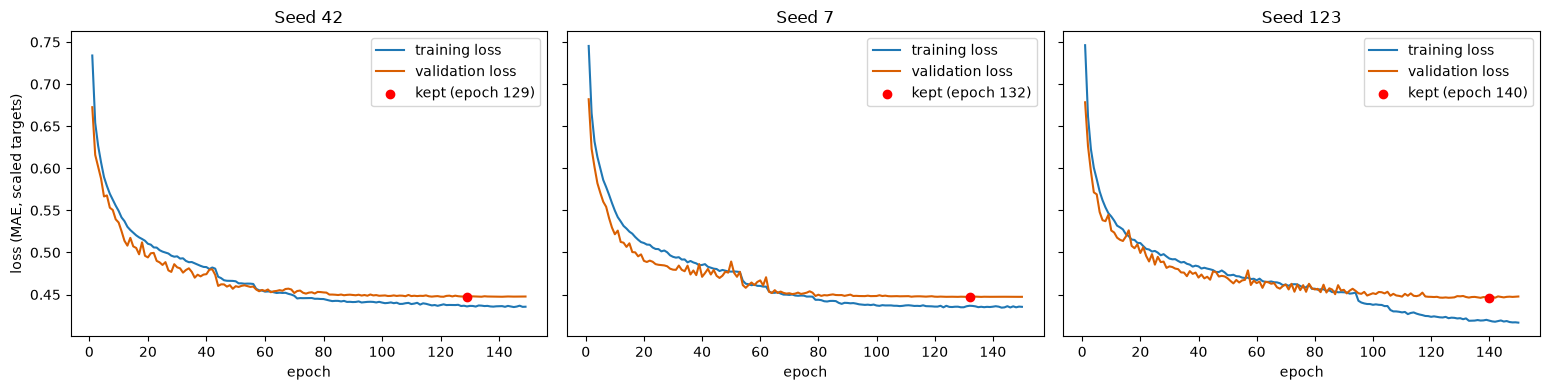

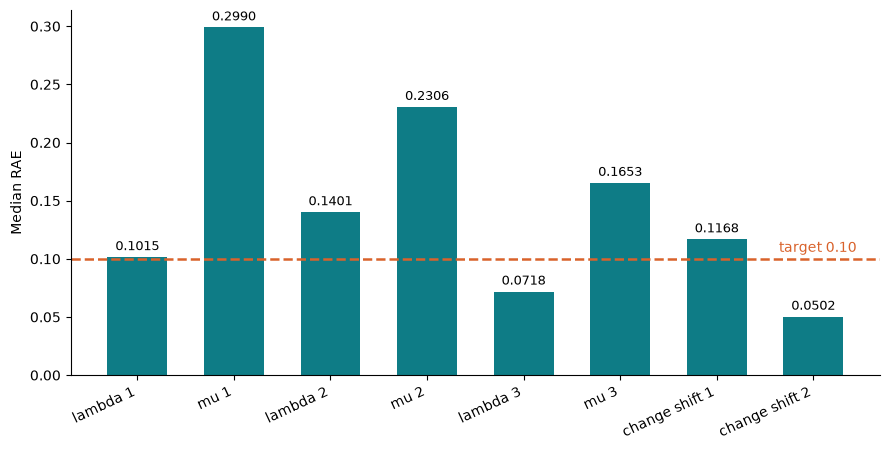

Saved the figures in /content/


In [ ]:
# Plots of the final model. Loss of every seed, and median RAE of each value.

# Folder where the pictures are saved.
OUT_DIR = "/content/"
# Names of the 8 values for the plot labels.
names = ["lambda 1", "mu 1", "lambda 2", "mu 2", "lambda 3", "mu 3", "change shift 1", "change shift 2"]

for tag in RANGE_TAGS:
    pooled = all_tables[tag]["pooled"]

    # Training and validation loss of every seed
    fig, axes = plt.subplots(1, len(SEEDS), figsize=(5.2 * len(SEEDS), 4.0), sharey=True, squeeze=False)
    for n in range(len(SEEDS)):
        seed = SEEDS[n]
        history = ALL_HISTORIES[tag][seed]
        epochs = list(range(1, len(history["loss"]) + 1))
        best = int(np.argmin(history["val_loss"]))
        ax = axes[0][n]
        ax.plot(epochs, history["loss"], label="training loss", color="#1f77b4")
        ax.plot(epochs, history["val_loss"], label="validation loss", color="#d95f02")
        ax.scatter([best + 1], [history["val_loss"][best]], color="red", zorder=3, label="kept (epoch %d)" % (best + 1))
        ax.set_title("Seed %d" % seed)
        ax.set_xlabel("epoch")
        ax.legend()
    axes[0][0].set_ylabel("loss (" + LOSS.upper() + ", scaled targets)")
    fig.tight_layout()
    fig.savefig(OUT_DIR + "loss_curves_" + tag + ".png", dpi=200)
    plt.show()

    # Median RAE of the final model for each value
    values = []
    for name in TARGET_NAMES:
        values.append(float(pooled.loc[name, "Median RAE"]))
    fig, ax = plt.subplots(figsize=(9, 4.6))
    ax.bar(range(len(values)), values, color="#0E7C86", width=0.62)
    ax.axhline(TARGET_SCORE, color="#D9622B", linestyle="--", linewidth=1.8)
    ax.text(len(values) - 0.55, TARGET_SCORE + 0.006, "target %.2f" % TARGET_SCORE, color="#D9622B", ha="right")
    for n in range(len(values)):
        ax.text(n, values[n] + 0.006, "%.4f" % values[n], ha="center", fontsize=9)
    ax.set_xticks(range(len(values)))
    ax.set_xticklabels(names, rotation=25, ha="right")
    ax.set_ylabel("Median RAE")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    fig.tight_layout()
    fig.savefig(OUT_DIR + "median_rae_" + tag + ".png", dpi=200)
    plt.show()

    print("Saved the figures in " + OUT_DIR)
